# DeepEval results: architecture and thinking-mode comparison

This notebook compares the 24 setup variants (S1–S8 × variants a–d) on the DeepEval scores in
`results/deepeval/scored_merged_dedup.csv`, and tests the two study hypotheses from `EXPERIMENT.md`:

| | Hypothesis | Setups | What we measure |
|---|---|---|---|
| **H1** | Letting agents make their own tool calls is more flexible and might be faster | S1–S4 (agentic) | Wall-clock latency, LLM calls, tokens; handling of the non-routine cases; tool-path diversity |
| **H2** | A deterministic, code-controlled flow succeeds more often and gives more consistent results | S5–S8 (graph) | Success rates; spread of scores across cases, variants and repeated runs |

**Design.** Each agentic setup has a graph counterpart that differs *only* in control style:
S1↔S5, S2↔S6, S3↔S7, S4↔S8, with the same variant letter. Each of the 13 cases was run once per variant,
which gives **12 matched variant pairs × 13 cases = 156 paired observations**. The control-style tests below use
these pairs (Wilcoxon signed-rank for scores and latency, exact McNemar for pass/fail). That removes case difficulty,
agent count, policy mode and strategy from the comparison.

**Thinking modes** (the variants): `react` picks one step at a time; `plan_execute` plans every step up front and
replans only on an error. Multi-agent variants c and d mix the two strategies between supervisor and specialists.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)

# Repo root, found whether the notebook runs from results/deepeval or the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "EXPERIMENT.md").exists())
CSV = ROOT / "results/deepeval/scored_merged_dedup.csv"
RAW_DIR = ROOT / "deepeval"
FIG_DIR = ROOT / "results/deepeval/figures"
FIG_DIR.mkdir(exist_ok=True)

# Colours: categorical slot 1 (blue) = agentic, slot 2 (orange) = graph; one-hue ramp for heatmaps
C_AGENTIC, C_GRAPH = "#2a78d6", "#eb6834"
CONTROL_PAL = {"agentic": C_AGENTIC, "graph": C_GRAPH}
SEQ = sns.light_palette("#2a78d6", as_cmap=True)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 9, "legend.frameon": False,
    "lines.linewidth": 2,
})

## 1. Load and label the data

In [2]:
df = pd.read_csv(CSV)

df["family"] = df["setup"].str[:2].str.upper()           # S1..S8
df["variant"] = df["setup"].str[-1]                      # a..d
fam_num = df["family"].str[1].astype(int)
df["control"] = np.where(fam_num <= 4, "agentic", "graph")
df["agents"] = np.where(fam_num.isin([1, 2, 5, 6]), "single", "multi")
df["policy"] = np.where(fam_num % 2 == 1, "RAG", "SKILL")

SINGLE_STRAT = {"a": "react", "b": "plan_execute"}
MULTI_STRAT = {"a": "react / react", "b": "plan / plan", "c": "react / plan", "d": "plan / react"}
df["strategy"] = np.where(df["agents"] == "single", df["variant"].map(SINGLE_STRAT), df["variant"].map(MULTI_STRAT))
# The "thinking mode" of whoever makes the tool calls (the agent, or the specialists in multi-agent setups)
df["worker_strategy"] = df["variant"].map({"a": "react", "b": "plan_execute", "c": "plan_execute", "d": "react"})

# Matched pair across control style: same agent count, policy and variant (S1-a <-> S5-a, ...)
df["pair_id"] = df["agents"] + "-" + df["policy"] + "-" + df["variant"]
df["arch"] = df["agents"] + " · " + df["control"]

df[["setup", "family", "variant", "control", "agents", "policy", "strategy", "pair_id"]].drop_duplicates().reset_index(drop=True)

,setup,family,variant,control,agents,policy,strategy,pair_id
0,s1-a,S1,a,agentic,single,RAG,react,single-RAG-a
1,s1-b,S1,b,agentic,single,RAG,plan_execute,single-RAG-b
2,s2-a,S2,a,agentic,single,SKILL,react,single-SKILL-a
3,s2-b,S2,b,agentic,single,SKILL,plan_execute,single-SKILL-b
4,s3-a,S3,a,agentic,multi,RAG,react / react,multi-RAG-a
5,s3-b,S3,b,agentic,multi,RAG,plan / plan,multi-RAG-b
6,s3-c,S3,c,agentic,multi,RAG,react / plan,multi-RAG-c
7,s3-d,S3,d,agentic,multi,RAG,plan / react,multi-RAG-d
8,s4-a,S4,a,agentic,multi,SKILL,react / react,multi-SKILL-a
9,s4-b,S4,b,agentic,multi,SKILL,plan / plan,multi-SKILL-b


### 1a. Join latency and cost from the raw run logs

The scored CSV has no timing, so latency, LLM calls, tokens and tool calls come from the raw run JSONL files in
`deepeval/`. A multi-turn case (EVAL-12, EVAL-13) has one `workflow_end` event per turn; those are summed.

EVAL-01 was run twice for every setup in `results.jsonl`, and the deduped CSV kept the **later** run, so we keep the last
raw row per (case, setup, source). The assert checks that every scored row found its run and that ticket statuses agree.
The second EVAL-01 run is kept aside for the run-to-run consistency check in §6.

In [3]:
SOURCES = {"results.jsonl": "scored",
           "new_cases_results_all.jsonl": "new_cases_results_all",
           "new_cases_results_errors_retry.jsonl": "errors_retry"}

def summarise_run(row):
    events = row["trace"].get("events", [])
    ends = [e for e in events if e["kind"] == "workflow_end"]
    calls = [e for e in events if e["kind"] == "llm_call"]
    return {
        "case_id": row["case_id"], "setup": row["setup"],
        "raw_status": row["ticket_status"],
        "elapsed_s": sum(e.get("elapsed_s", 0) for e in ends),
        "llm_calls": sum(e.get("llm_calls", 0) for e in ends),
        "input_tokens": sum(e.get("input_tokens", 0) for e in calls),
        "output_tokens": sum(e.get("output_tokens", 0) for e in calls),
        "tool_calls": len(row["tools_called"]),
        "tool_path": " > ".join(t["name"] for t in row["tools_called"]),
        "write_count": len(row.get("writes") or []),
        "models": ",".join(sorted({e.get("model", "?") for e in calls})),
        "turns": len(ends),
    }

raw = []
for fname, source in SOURCES.items():
    for i, line in enumerate((RAW_DIR / fname).open()):
        rec = summarise_run(json.loads(line)) | {"source_file": source, "run_idx": i}
        raw.append(rec)
raw = pd.DataFrame(raw)

key = ["case_id", "setup", "source_file"]
raw = raw.sort_values("run_idx")
raw_kept = raw.drop_duplicates(key, keep="last")
raw_repeat = raw[raw.duplicated(key, keep=False)]          # EVAL-01's two runs, for section 6

df = df.merge(raw_kept.drop(columns="run_idx"), on=key, how="left", validate="one_to_one")
assert df["elapsed_s"].notna().all(), "a scored row has no raw run"
assert (df["raw_status"] == df["ticket_status"]).all(), "raw and scored ticket statuses disagree"
df["total_tokens"] = df["input_tokens"] + df["output_tokens"]

print(f"{len(df)} scored rows = {df.setup.nunique()} setups × {df.case_id.nunique()} cases")
print("Agent LLM(s) used:", df["models"].value_counts().to_dict())

312 scored rows = 24 setups × 13 cases
Agent LLM(s) used: {'openai/gpt-oss-120b': 312}


### 1b. Case catalogue

In [4]:
cases = pd.concat([pd.read_csv(RAW_DIR / "cases_original.csv"), pd.read_csv(RAW_DIR / "cases.csv")])
cases = cases.drop_duplicates("case_id", keep="last").set_index("case_id")[["focus", "expected_ticket_status"]].sort_index()

# Routine single-lookup cases vs the cases that need the agent to adapt (writes, safety, injection, clarification, replay)
ROUTINE = [f"EVAL-0{i}" for i in range(1, 9)]
cases["kind"] = np.where(cases.index.isin(ROUTINE), "routine lookup", "non-routine")
df = df.merge(cases[["focus", "kind"]], left_on="case_id", right_index=True)
cases

,focus,expected_ticket_status,kind
case_id,,,
EVAL-01,Order contents lookup: items in the power-bank...,resolved,routine lookup
EVAL-02,Order status lookup: processing order,resolved,routine lookup
EVAL-03,Payment lookup: captured payment status,resolved,routine lookup
EVAL-04,Return lookup: pending fault claim status,resolved,routine lookup
EVAL-05,Tracking lookup: delivered shipment status,resolved,routine lookup
EVAL-06,Policy lookup: ordinary return request window,resolved,routine lookup
EVAL-07,Customer order lookup: identify processing order,resolved,routine lookup
EVAL-08,Shipment lookup: carrier and tracking number,resolved,routine lookup
EVAL-09,"Refund processing: approved bottle return, SGD 20",resolved,non-routine


## 2. Define success

**The judge's `_success` flags are not reliable.** For several G-Eval metrics a score of 1.0 is often flagged
`False` (for `trajectory_quality_trace`, 102 rows scored 1.0 are marked failed). So every pass/fail here is
re-derived as **score ≥ 0.5**, DeepEval's default threshold:

In [5]:
CORE = ["answer_correctness", "tool_correctness", "argument_correctness",
        "task_completion_trace", "step_efficiency_trace", "trajectory_quality_trace"]
PLAN = ["plan_adherence_trace", "plan_quality_trace"]
SHORT = {"answer_correctness": "answer", "tool_correctness": "tool", "argument_correctness": "argument",
         "task_completion_trace": "task completion", "step_efficiency_trace": "step efficiency",
         "trajectory_quality_trace": "trajectory", "plan_adherence_trace": "plan adherence",
         "plan_quality_trace": "plan quality"}
THRESH = 0.5

flag_check = pd.DataFrame({
    m: {"score ≥ 0.5 but flagged False": ((df[f"{m}_score"] >= THRESH) & (df[f"{m}_success"].astype(str) == "False")).sum(),
        "score < 0.5 but flagged True": ((df[f"{m}_score"] < THRESH) & (df[f"{m}_success"].astype(str) == "True")).sum()}
    for m in CORE + PLAN}).T
display(flag_check)

for m in CORE + PLAN:
    df[f"{m}_pass"] = (df[f"{m}_score"] >= THRESH).where(df[f"{m}_score"].notna())

,score ≥ 0.5 but flagged False,score < 0.5 but flagged True
answer_correctness,73,0
tool_correctness,0,0
argument_correctness,0,0
task_completion_trace,39,0
step_efficiency_trace,71,0
trajectory_quality_trace,129,0
plan_adherence_trace,28,0
plan_quality_trace,42,0


Outcome definitions used throughout:

| Outcome | Definition |
|---|---|
| `status_ok` | Final ticket status equals the expected one (`resolved` / `awaiting_human`) |
| **`success`** | **End-to-end success:** `status_ok` **and** answer correctness ≥ 0.5 **and** task completion ≥ 0.5 |
| `quality` | Mean of the six core metric scores (the plan metrics exist only for plan_execute variants, so they are left out) |

The plan metrics are only scored where a plan exists (variants b, c, d), so they appear only in §5.

In [6]:
df["status_ok"] = df["ticket_status"] == df["expected_ticket_status"]
df["success"] = df["status_ok"] & df["answer_correctness_pass"].astype(bool) & df["task_completion_trace_pass"].astype(bool)
df["quality"] = df[[f"{m}_score" for m in CORE]].mean(axis=1)
print(f"Overall end-to-end success: {df.success.mean():.1%}   status match: {df.status_ok.mean():.1%}")

Overall end-to-end success: 73.4%   status match: 93.6%


## 3. Leaderboard: all 24 variants

In [7]:
def summarise(g):
    out = {
        "n": len(g),
        "success %": 100 * g["success"].mean(),
        "status ok %": 100 * g["status_ok"].mean(),
        "quality": g["quality"].mean(),
        "quality sd": g["quality"].std(),
    }
    out |= {SHORT[m]: g[f"{m}_score"].mean() for m in CORE}
    out |= {"median s": g["elapsed_s"].median(), "llm calls": g["llm_calls"].mean(),
            "k tokens": g["total_tokens"].mean() / 1000, "tool calls": g["tool_calls"].mean()}
    return pd.Series(out)

board = (df.groupby(["setup", "control", "agents", "policy", "strategy"]).apply(summarise, include_groups=False)
           .reset_index().sort_values(["success %", "quality"], ascending=False))
board.style.format(precision=2).format({"n": "{:.0f}", "success %": "{:.0f}", "status ok %": "{:.0f}"}) \
     .background_gradient(cmap=SEQ, subset=["success %", "quality"]) \
     .background_gradient(cmap=SEQ.reversed(), subset=["median s"]).hide(axis="index")

setup,control,agents,policy,strategy,n,success %,status ok %,quality,quality sd,answer,tool,argument,task completion,step efficiency,trajectory,median s,llm calls,k tokens,tool calls
s1-b,agentic,single,RAG,plan_execute,13,85,100,0.868162,0.144010,0.753846,0.965385,0.858974,0.938462,0.861538,0.830769,29.886300,5.769231,12.469077,2.692308
s2-a,agentic,single,SKILL,react,13,85,100,0.867628,0.140334,0.746154,0.888462,0.863462,0.869231,0.984615,0.853846,24.927900,8.000000,16.603231,2.461538
s4-d,agentic,multi,SKILL,plan / react,13,85,100,0.864015,0.110686,0.746154,0.880769,0.764857,0.946154,0.946154,0.900000,37.749900,10.307692,22.397923,3.076923
s2-b,agentic,single,SKILL,plan_execute,13,77,92,0.887271,0.100115,0.769231,0.953846,0.785165,0.961538,0.969231,0.884615,39.007000,5.615385,12.920846,3.384615
s7-c,graph,multi,RAG,react / plan,13,77,100,0.858974,0.136696,0.676923,0.950000,0.788462,0.953846,0.900000,0.884615,35.006200,9.769231,20.566231,3.076923
s6-a,graph,single,SKILL,react,13,77,100,0.857479,0.162119,0.730769,0.884615,0.775641,0.876923,0.961538,0.915385,28.067400,9.076923,17.809385,3.384615
s4-a,agentic,multi,SKILL,react / react,13,77,92,0.843784,0.133109,0.753846,0.923077,0.793473,0.861538,0.876923,0.853846,34.297700,11.846154,22.665692,2.769231
s1-a,agentic,single,RAG,react,13,77,92,0.837179,0.179396,0.746154,0.869231,0.884615,0.892308,0.892308,0.738462,24.912000,7.384615,14.283462,1.923077
s8-d,graph,multi,SKILL,plan / react,13,77,85,0.836966,0.182219,0.669231,0.907692,0.814103,0.792308,0.907692,0.930769,30.310500,12.153846,23.778769,3.692308
s6-b,graph,single,SKILL,plan_execute,13,77,92,0.835860,0.173295,0.676698,0.938462,0.807692,0.900000,0.869231,0.823077,29.534500,8.230769,19.695692,4.076923


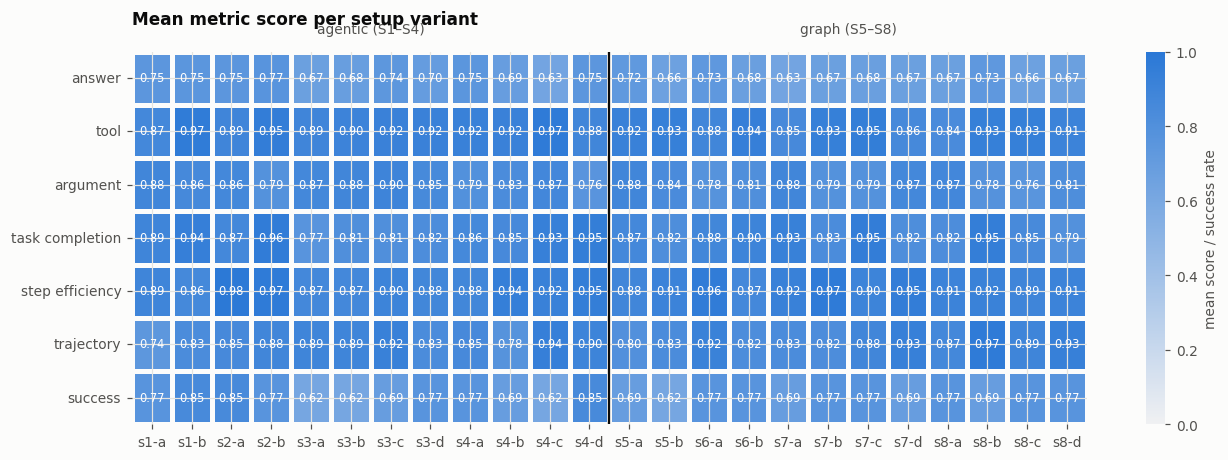

In [8]:
order = sorted(df.setup.unique())
heat = df.groupby("setup")[[f"{m}_score" for m in CORE] + ["success"]].mean().loc[order]
heat.columns = [SHORT.get(c.replace("_score", ""), c) for c in heat.columns]

fig, ax = plt.subplots(figsize=(14, 4.4))
sns.heatmap(heat.T, cmap=SEQ, vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7.5},
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "mean score / success rate"}, ax=ax)
ax.axvline(12, color=INK, lw=1.5)
ax.text(6, -0.35, "agentic (S1–S4)", ha="center", color=INK2)
ax.text(18, -0.35, "graph (S5–S8)", ha="center", color=INK2)
ax.set(xlabel="", ylabel="")
ax.set_title("Mean metric score per setup variant", pad=18)
fig.savefig(FIG_DIR / "metric_heatmap.png");

## 4. H1: agentic control is more flexible and faster

### 4a. Speed and cost (paired)

Each agentic row is matched with its graph counterpart on the same case (e.g. `s3-c` × EVAL-05 ↔ `s7-c` × EVAL-05).
The tests are on the paired difference **agentic − graph**, so a negative value means agentic is faster or cheaper.

In [9]:
def paired(df, col):
    w = df.pivot_table(index=["pair_id", "case_id"], columns="control", values=col, aggfunc="first").dropna()
    return w["agentic"], w["graph"]

def bootstrap_ci(x, fn=np.median, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    boots = fn(rng.choice(x, (n, len(x)), replace=True), axis=1)
    return np.percentile(boots, [2.5, 97.5])

rows = []
for col, label in [("elapsed_s", "latency (s)"), ("llm_calls", "LLM calls"),
                   ("total_tokens", "tokens"), ("tool_calls", "tool calls")]:
    a, g = paired(df, col)
    d = a - g
    lo, hi = bootstrap_ci(d)
    p = stats.wilcoxon(a, g, zero_method="zsplit").pvalue
    rows.append({"measure": label, "pairs": len(d), "agentic median": a.median(), "graph median": g.median(),
                 "agentic mean": a.mean(), "graph mean": g.mean(),
                 "median diff (A−G)": d.median(), "95% CI of median diff": f"[{lo:.1f}, {hi:.1f}]",
                 "mean diff (A−G)": d.mean(),
                 "agentic lower in %": 100 * (d < 0).mean(), "Wilcoxon p": p})
speed = pd.DataFrame(rows)
display(speed)

# The same paired latency test, split into routine lookups and non-routine cases
rows = []
for kind, g in df.groupby("kind"):
    a, gg = paired(g, "elapsed_s")
    rows.append({"cases": kind, "pairs": len(a), "agentic median s": a.median(), "graph median s": gg.median(),
                 "agentic mean s": a.mean(), "graph mean s": gg.mean(),
                 "agentic faster in %": 100 * (a < gg).mean(),
                 "Wilcoxon p": stats.wilcoxon(a, gg, zero_method="zsplit").pvalue})
speed_kind = pd.DataFrame(rows)
display(speed_kind.style.format(precision=1).format({"Wilcoxon p": "{:.2g}", "agentic faster in %": "{:.0f}"}))

# Per-case median latency: where the graph's fixed stages cost time
per_case_lat = df.pivot_table(index="case_id", columns="control", values="elapsed_s", aggfunc="median")
per_case_lat["graph / agentic"] = per_case_lat["graph"] / per_case_lat["agentic"]
per_case_lat.join(cases["focus"]).round(2)

,measure,pairs,agentic median,graph median,agentic mean,graph mean,median diff (A−G),95% CI of median diff,mean diff (A−G),agentic lower in %,Wilcoxon p
0,latency (s),156,35.114,31.649,39.490,52.066,0.207,"[-1.0, 1.5]",-12.576,49.359,3.493e-01
1,LLM calls,156,8.000,8.000,8.705,10.128,0.000,"[-1.0, 0.0]",-1.423,49.359,1.369e-07
2,tokens,156,12174.000,10544.500,17641.192,20499.083,1047.000,"[475.0, 1517.0]",-2857.891,33.333,1.257e-01
3,tool calls,156,2.000,2.000,2.878,3.385,0.000,"[0.0, 0.0]",-0.506,28.205,1.237e-02


,cases,pairs,agentic median s,graph median s,agentic mean s,graph mean s,agentic faster in %,Wilcoxon p
0,non-routine,60,39.459800,58.618650,48.103108,86.058158,73,6.2e-06
1,routine lookup,96,33.645650,29.689950,34.106246,30.820649,34,0.00042


,agentic,graph,graph / agentic,focus
case_id,,,,
EVAL-01,31.85,28.70,0.90,Order contents lookup: items in the power-bank...
EVAL-02,34.09,28.10,0.82,Order status lookup: processing order
EVAL-03,36.24,30.93,0.85,Payment lookup: captured payment status
EVAL-04,33.95,32.39,0.95,Return lookup: pending fault claim status
EVAL-05,28.68,29.82,1.04,Tracking lookup: delivered shipment status
EVAL-06,40.04,30.65,0.77,Policy lookup: ordinary return request window
EVAL-07,30.48,29.99,0.98,Customer order lookup: identify processing order
EVAL-08,31.83,26.28,0.83,Shipment lookup: carrier and tracking number
EVAL-09,36.39,100.02,2.75,"Refund processing: approved bottle return, SGD 20"


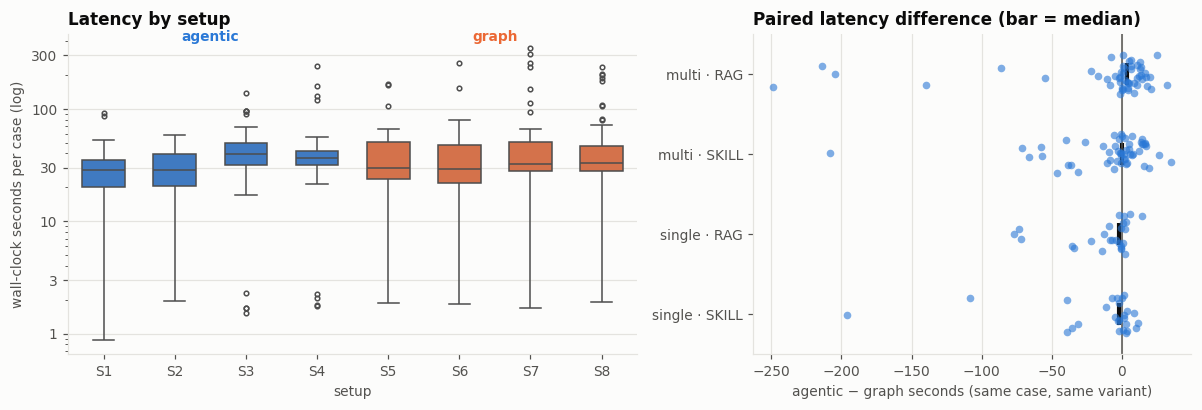

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})

sns.boxplot(data=df, x="family", y="elapsed_s", hue="control", palette=CONTROL_PAL, order=[f"S{i}" for i in range(1, 9)],
            width=0.6, linewidth=1, fliersize=3, ax=axes[0], legend=False)
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
axes[0].set_yticks([1, 3, 10, 30, 100, 300])
axes[0].set(xlabel="setup", ylabel="wall-clock seconds per case (log)", title="Latency by setup")
for x, t in [(1.5, "agentic"), (5.5, "graph")]:
    axes[0].text(x, 500, t, ha="center", va="top", color=CONTROL_PAL[t], fontweight="bold")

a, g = paired(df, "elapsed_s")
diff = (a - g).reset_index(name="diff")
diff["arch"] = diff["pair_id"].str.split("-").str[:2].str.join(" · ")
sns.stripplot(data=diff, y="arch", x="diff", color=C_AGENTIC, alpha=0.6, size=5, jitter=0.25, ax=axes[1])
sns.pointplot(data=diff, y="arch", x="diff", estimator=np.median, color=INK, markers="|", markersize=14,
              linestyle="none", errorbar=None, ax=axes[1])
axes[1].axvline(0, color=INK2, lw=1)
axes[1].set(xlabel="agentic − graph seconds (same case, same variant)", ylabel="",
            title="Paired latency difference (bar = median)")
fig.tight_layout(); fig.savefig(FIG_DIR / "h1_latency.png");

In [11]:
# Where does the time go? Latency by architecture and thinking mode
lat = df.pivot_table(index=["agents", "strategy"], columns="control", values="elapsed_s", aggfunc="median")
lat["agentic − graph"] = lat["agentic"] - lat["graph"]
lat.round(1)

control               agentic  graph  agentic − graph
agents strategy                                      
multi  plan / plan       41.0   42.2             -1.2
       plan / react      37.4   31.1              6.4
       react / plan      37.2   33.5              3.7
       react / react     35.5   28.7              6.7
single plan_execute      30.3   30.9             -0.5
       react             24.9   27.6             -2.6

### 4b. Flexibility

Flexibility can't be measured directly, so we use three proxies:

1. **Non-routine cases.** Does agentic control do better where the fixed flow might not fit: injection (EVAL-11),
   asking for a missing order ID (EVAL-12), replayed cancellation (EVAL-13), refund write (EVAL-09) and safety
   escalation (EVAL-10)?
2. **Tool-path diversity.** How many distinct tool sequences a control style produces for the same case. More paths
   means more adaptive behaviour, but also less predictable behaviour.
3. **Tool and argument correctness.** Does the freedom lead to choosing the right tools with the right arguments?

In [12]:
kind_tbl = df.groupby(["kind", "control"]).agg(
    success=("success", "mean"), status_ok=("status_ok", "mean"), quality=("quality", "mean"),
    median_s=("elapsed_s", "median")).unstack("control")
display(kind_tbl.style.format("{:.2f}"))

case_tbl = df.pivot_table(index=["case_id"], columns="control", values="success", aggfunc="mean")
case_tbl["agentic − graph"] = case_tbl["agentic"] - case_tbl["graph"]
case_tbl = case_tbl.join(cases[["focus", "kind"]])
case_tbl.style.format({"agentic": "{:.0%}", "graph": "{:.0%}", "agentic − graph": "{:+.0%}"}) \
        .background_gradient(cmap="RdBu", vmin=-0.5, vmax=0.5, subset=["agentic − graph"])

,agentic,graph,agentic − graph,focus,kind
case_id,,,,,
EVAL-01,83%,92%,-8%,Order contents lookup: items in the power-bank order,routine lookup
EVAL-02,67%,75%,-8%,Order status lookup: processing order,routine lookup
EVAL-03,83%,83%,+0%,Payment lookup: captured payment status,routine lookup
EVAL-04,100%,83%,+17%,Return lookup: pending fault claim status,routine lookup
EVAL-05,92%,100%,-8%,Tracking lookup: delivered shipment status,routine lookup
EVAL-06,100%,100%,+0%,Policy lookup: ordinary return request window,routine lookup
EVAL-07,100%,100%,+0%,Customer order lookup: identify processing order,routine lookup
EVAL-08,100%,100%,+0%,Shipment lookup: carrier and tracking number,routine lookup
EVAL-09,50%,8%,+42%,"Refund processing: approved bottle return, SGD 20",non-routine


In [13]:
div = (df.groupby(["case_id", "control"]).agg(distinct_paths=("tool_path", "nunique"), runs=("tool_path", "size"),
                                              tool_calls_sd=("tool_calls", "std"))
         .unstack("control"))
display(div.round(2))
print("Mean distinct tool paths per case (out of 12 runs):",
      df.groupby(["case_id", "control"]).tool_path.nunique().groupby("control").mean().round(2).to_dict())

tc = df.groupby("control")[["tool_correctness_score", "argument_correctness_score", "step_efficiency_trace_score"]].mean()
tc.columns = ["tool", "argument", "step efficiency"]
tc.round(3)

distinct_paths          runs       tool_calls_sd      
control        agentic graph agentic graph       agentic graph
case_id                                                       
EVAL-01              2     2      12    12          0.29  0.39
EVAL-02              3     3      12    12          0.79  0.98
EVAL-03              3     2      12    12          0.83  0.00
EVAL-04              2     4      12    12          0.51  1.16
EVAL-05              3     4      12    12          0.87  0.75
EVAL-06              3     2      12    12          0.67  0.52
EVAL-07              2     1      12    12          0.29  0.00
EVAL-08              4     2      12    12          0.49  0.29
EVAL-09              9     9      12    12          1.31  2.50
EVAL-10             12    11      12    12          1.19  2.26
EVAL-11              1     1      12    12          0.00  0.00
EVAL-12              9     5      12    12          1.31  1.44
EVAL-13             12    12      12    12          6.69  4.34

Mean distinct tool paths per case (out of 12 runs): {'agentic': 5.0, 'graph': 4.46}


,tool,argument,step efficiency
control,,,
agentic,0.917,0.846,0.909
graph,0.908,0.822,0.916


## 5. H2: deterministic flow succeeds more often and is more consistent

### 5a. Success frequency (paired)

For binary outcomes the exact McNemar test uses only the *discordant* pairs: one side passes, the other fails.

In [14]:
def mcnemar_exact(a, g):
    a, g = a.astype(bool), g.astype(bool)
    b, c = int((a & ~g).sum()), int((~a & g).sum())        # agentic-only passes, graph-only passes
    p = stats.binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
    return b, c, p

rows = []
for col, label in [("success", "end-to-end success"), ("status_ok", "ticket status correct")] + \
                  [(f"{m}_pass", SHORT[m] + " ≥ 0.5") for m in CORE]:
    a, g = paired(df, col)
    b, c, p = mcnemar_exact(a, g)
    rows.append({"outcome": label, "agentic rate": a.astype(float).mean(), "graph rate": g.astype(float).mean(),
                 "only agentic passes": b, "only graph passes": c, "McNemar p": p})
succ = pd.DataFrame(rows)
display(succ.style.format({"agentic rate": "{:.1%}", "graph rate": "{:.1%}", "McNemar p": "{:.3f}"}))

rows = []
for m in CORE + ["quality"]:
    col = m if m == "quality" else f"{m}_score"
    a, g = paired(df, col)
    p = stats.wilcoxon(a, g, zero_method="zsplit").pvalue
    rows.append({"score": SHORT.get(m, m), "agentic mean": a.mean(), "graph mean": g.mean(),
                 "mean diff (A−G)": (a - g).mean(), "Wilcoxon p": p})
pd.DataFrame(rows).round(3)

,outcome,agentic rate,graph rate,only agentic passes,only graph passes,McNemar p
0,end-to-end success,73.7%,73.1%,15,14,1.000
1,ticket status correct,92.3%,94.9%,8,12,0.503
2,answer ≥ 0.5,80.1%,75.6%,14,7,0.189
3,tool ≥ 0.5,96.8%,95.5%,6,4,0.754
4,argument ≥ 0.5,88.5%,85.3%,9,4,0.267
5,task completion ≥ 0.5,86.5%,87.2%,12,13,1.000
6,step efficiency ≥ 0.5,97.4%,94.9%,8,4,0.388
7,trajectory ≥ 0.5,88.5%,88.5%,15,15,1.000


,score,agentic mean,graph mean,mean diff (A−G),Wilcoxon p
0,answer,0.719,0.681,0.039,0.196
1,tool,0.917,0.908,0.009,0.358
2,argument,0.846,0.822,0.024,0.321
3,task completion,0.872,0.867,0.005,0.650
4,step efficiency,0.909,0.916,-0.007,0.131
5,trajectory,0.860,0.875,-0.015,0.353
6,quality,0.854,0.845,0.009,0.782


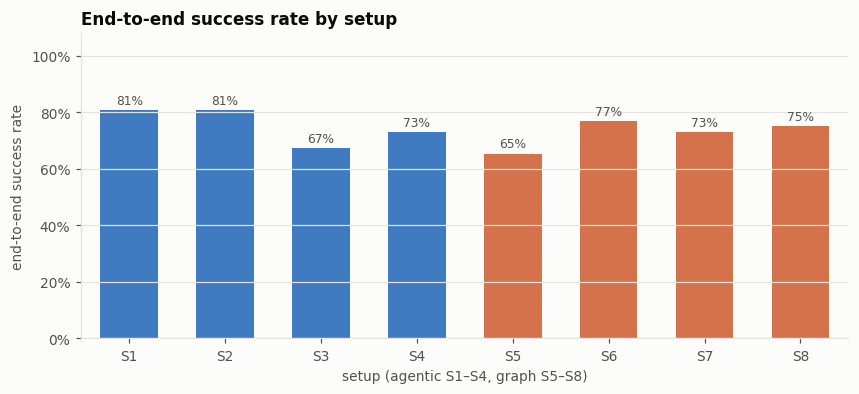

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.6))
plot = df.groupby(["family", "control"])["success"].mean().reset_index()
sns.barplot(data=plot, x="family", y="success", hue="control", palette=CONTROL_PAL, dodge=False,
            order=[f"S{i}" for i in range(1, 9)], width=0.6, ax=ax, legend=False)
for p_, v in zip(ax.patches, plot.set_index("family").loc[[f"S{i}" for i in range(1, 9)], "success"]):
    ax.annotate(f"{v:.0%}", (p_.get_x() + p_.get_width() / 2, v), ha="center", va="bottom", fontsize=8, color=INK2,
                xytext=(0, 2), textcoords="offset points")
ax.set(ylim=(0, 1.08), xlabel="setup (agentic S1–S4, graph S5–S8)", ylabel="end-to-end success rate",
       title="End-to-end success rate by setup")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.savefig(FIG_DIR / "h2_success.png");

### 5b. Consistency

There was one trial per case and variant, so consistency is measured three ways:

1. **Across variants** (thinking-mode sensitivity). For the same case and setup family, how much does the quality score
   vary between variants a–d? A low spread means the result doesn't depend on which strategy you pick.
2. **Across cases.** The spread of a setup's quality score over the 13 cases (a lower SD means steadier performance
   whatever the request).
3. **Latency variability.** The coefficient of variation of wall-clock time.

The variance is compared with Levene's test (Brown–Forsythe, median-centred). §6 adds run-to-run repeatability from
the duplicate EVAL-01 runs.

In [16]:
# 1. across variants: SD of quality and success agreement within (family, case)
within = df.groupby(["control", "family", "case_id"]).agg(
    quality_sd=("quality", "std"), success_agree=("success", lambda s: s.all() or (~s).all()),
    status_agree=("status_ok", lambda s: s.all() or (~s).all()))
cons_variant = within.groupby("control").agg(
    mean_quality_sd=("quality_sd", "mean"), all_variants_agree_on_success=("success_agree", "mean"),
    all_variants_agree_on_status=("status_agree", "mean"))

# 2. across cases: SD of quality per setup variant
across_case = df.groupby(["control", "setup"])["quality"].std().rename("quality_sd_over_cases")
# 3. latency CV per setup variant
lat_cv = df.groupby(["control", "setup"])["elapsed_s"].agg(lambda s: s.std() / s.mean()).rename("latency_cv")

cons = cons_variant.join(across_case.groupby("control").mean()).join(lat_cv.groupby("control").mean())
display(cons.round(3))

def levene(col, data=df):
    return stats.levene(*[g[col].dropna() for _, g in data.groupby("control")], center="median").pvalue

print("Brown–Forsythe p, quality score (all rows):        ", round(levene("quality"), 4))
print("Brown–Forsythe p, latency (all rows):              ", round(levene("elapsed_s"), 4))
print("Brown–Forsythe p, quality SD across variants:      ",
      round(stats.levene(*[g.dropna() for _, g in within["quality_sd"].groupby("control")], center="median").pvalue, 4))

,mean_quality_sd,all_variants_agree_on_success,all_variants_agree_on_status,quality_sd_over_cases,latency_cv
control,,,,,
agentic,0.067,0.692,0.808,0.132,0.657
graph,0.058,0.846,0.904,0.162,1.083


Brown–Forsythe p, quality score (all rows):         0.1651
Brown–Forsythe p, latency (all rows):               0.0053
Brown–Forsythe p, quality SD across variants:       0.4336


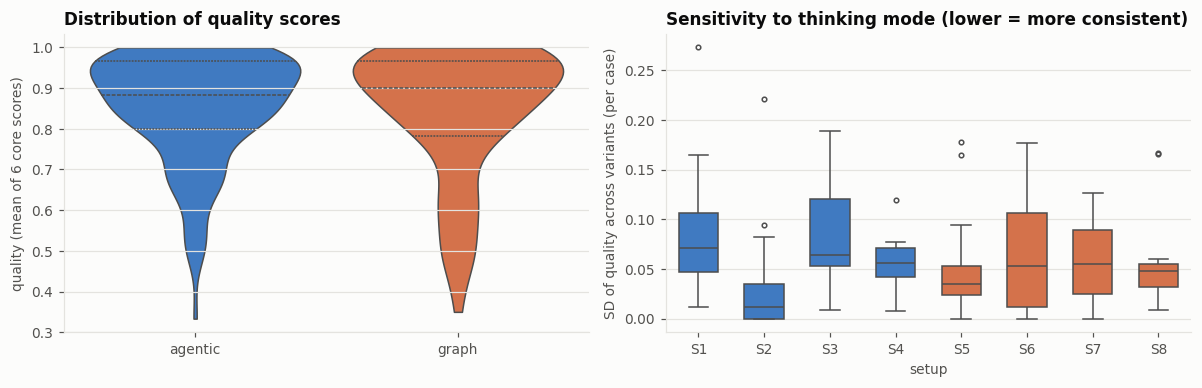

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.violinplot(data=df, x="control", y="quality", hue="control", palette=CONTROL_PAL, inner="quart",
               cut=0, linewidth=1, ax=axes[0], legend=False)
axes[0].set(xlabel="", ylabel="quality (mean of 6 core scores)", title="Distribution of quality scores")

w = within.reset_index()
sns.boxplot(data=w, x="family", y="quality_sd", hue="control", palette=CONTROL_PAL, dodge=False,
            order=[f"S{i}" for i in range(1, 9)], width=0.6, linewidth=1, fliersize=3, ax=axes[1], legend=False)
axes[1].set(xlabel="setup", ylabel="SD of quality across variants (per case)",
            title="Sensitivity to thinking mode (lower = more consistent)")
fig.tight_layout(); fig.savefig(FIG_DIR / "h2_consistency.png");

## 6. Run-to-run repeatability (EVAL-01 run twice)

EVAL-01 (order-contents lookup) ran twice for every setup. Only the second run was scored, but the raw logs of both
show whether a setup takes the **same tool path** and reaches the **same status** when repeated, and how much its
latency moves.

In [18]:
rep = raw_repeat.sort_values("run_idx").groupby("setup").agg(
    same_tool_path=("tool_path", lambda s: s.nunique() == 1),
    same_status=("raw_status", lambda s: s.nunique() == 1),
    abs_latency_diff_s=("elapsed_s", lambda s: abs(s.iloc[-1] - s.iloc[0])),
    llm_call_diff=("llm_calls", lambda s: abs(s.iloc[-1] - s.iloc[0])))
rep["control"] = np.where(rep.index.str[1].astype(int) <= 4, "agentic", "graph")
display(rep.groupby("control").agg(setups=("same_status", "size"), same_tool_path=("same_tool_path", "mean"),
                                   same_status=("same_status", "mean"),
                                   mean_abs_latency_diff_s=("abs_latency_diff_s", "mean"),
                                   mean_llm_call_diff=("llm_call_diff", "mean")).round(2))
rep[~rep.same_tool_path | ~rep.same_status]

,setups,same_tool_path,same_status,mean_abs_latency_diff_s,mean_llm_call_diff
control,,,,,
agentic,12,0.58,1.0,12.41,0.50
graph,12,0.83,1.0,10.68,0.08


,same_tool_path,same_status,abs_latency_diff_s,llm_call_diff,control
setup,,,,,
s3-a,False,True,7.393,1,agentic
s3-b,False,True,33.780,1,agentic
s3-d,False,True,11.223,2,agentic
s4-a,False,True,11.325,0,agentic
s4-d,False,True,5.098,1,agentic
s5-a,False,True,9.533,1,graph
s6-b,False,True,7.924,0,graph


## 7. Architectures and thinking modes

The hypotheses are about control style, but each setup also varies agent count (single vs multi), policy source
(RAG vs SKILL) and thinking mode (react vs plan_execute). This section breaks each factor out and checks whether
the control-style effect holds within each.

In [19]:
fac = []
for factor in ["control", "agents", "policy", "worker_strategy"]:
    t = df.groupby(factor).agg(success=("success", "mean"), status_ok=("status_ok", "mean"),
                               quality=("quality", "mean"), quality_sd=("quality", "std"),
                               median_s=("elapsed_s", "median"), llm_calls=("llm_calls", "mean"))
    t.index = pd.MultiIndex.from_product([[factor], t.index])
    fac.append(t)
pd.concat(fac).style.format("{:.2f}").format({"success": "{:.0%}", "status_ok": "{:.0%}", "median_s": "{:.1f}"})

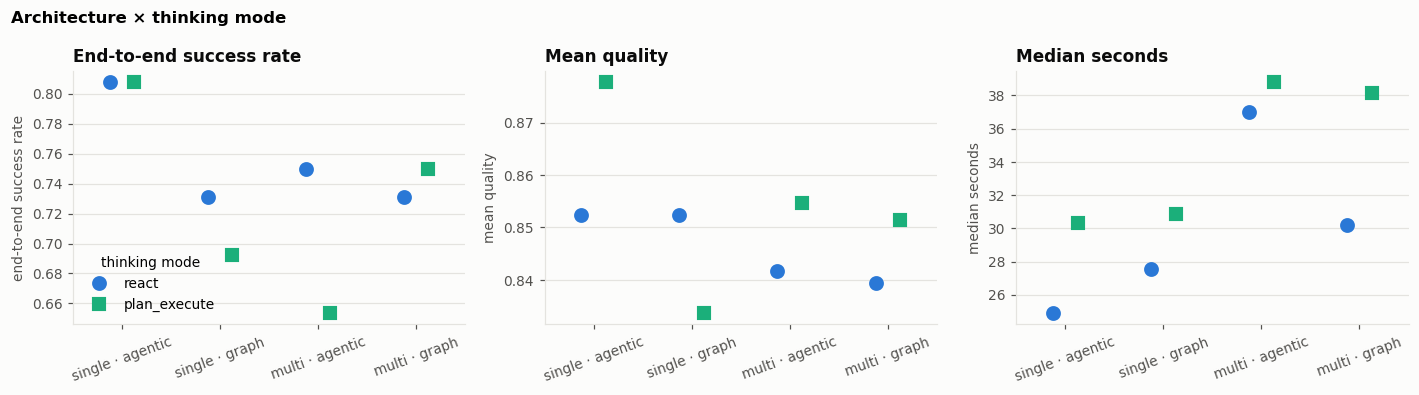

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
specs = [("success", "end-to-end success rate"), ("quality", "mean quality"), ("elapsed_s", "median seconds")]
for ax, (col, lab) in zip(axes, specs):
    est = np.median if col == "elapsed_s" else np.mean
    sns.pointplot(data=df, x="arch", y=col, hue="worker_strategy", estimator=est, errorbar=None,
                  order=["single · agentic", "single · graph", "multi · agentic", "multi · graph"],
                  palette=[C_AGENTIC, "#1baf7a"], hue_order=["react", "plan_execute"],
                  markers=["o", "s"], markersize=7, linestyle="none", dodge=0.25, ax=ax, legend=(ax is axes[0]))
    ax.set(xlabel="", ylabel=lab, title=lab.capitalize())
    ax.tick_params(axis="x", rotation=20)
axes[0].legend(title="thinking mode", loc="lower left")
fig.suptitle("Architecture × thinking mode", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG_DIR / "arch_thinking_mode.png");

In [21]:
# Multi-agent: all four supervisor/specialist combinations
multi = df[df.agents == "multi"].pivot_table(index="strategy", columns="control",
                                             values=["success", "quality", "elapsed_s"],
                                             aggfunc={"success": "mean", "quality": "mean", "elapsed_s": "median"})
multi.columns = [f"{v} · {c}" for v, c in multi.columns]
multi.index.name = "supervisor / specialists"
multi.round(2)

,elapsed_s · agentic,elapsed_s · graph,quality · agentic,quality · graph,success · agentic,success · graph
supervisor / specialists,,,,,,
plan / plan,40.97,42.16,0.84,0.86,0.65,0.73
plan / react,37.41,31.06,0.85,0.84,0.81,0.73
react / plan,37.15,33.47,0.87,0.84,0.65,0.77
react / react,35.47,28.74,0.83,0.84,0.69,0.73


In [22]:
# Plan metrics, only where a plan exists (variants b, c, d)
plan = df[df.plan_quality_trace_score.notna()]
plan.groupby(["control", "agents"])[[f"{m}_score" for m in PLAN]].mean().rename(columns=lambda c: SHORT[c[:-6]]).round(3)

plan adherence  plan quality
control agents                              
agentic multi            0.891         0.962
        single           0.992         0.988
graph   multi            0.914         0.938
        single           0.892         0.919

In [23]:
# Does the control-style effect hold within every architecture × thinking-mode slice?
rows = []
for (agents, policy, strat), g in df.groupby(["agents", "policy", "worker_strategy"]):
    a, gg = paired(g, "success")
    la, lg = paired(g, "elapsed_s")
    rows.append({"agents": agents, "policy": policy, "thinking mode": strat, "pairs": len(a),
                 "success A": a.mean(), "success G": gg.mean(),
                 "median s A": la.median(), "median s G": lg.median()})
slices = pd.DataFrame(rows)
slices["graph more successful"] = slices["success G"] > slices["success A"]
slices["agentic faster"] = slices["median s A"] < slices["median s G"]
slices.round(2)

,agents,policy,thinking mode,pairs,success A,success G,median s A,median s G,graph more successful,agentic faster
0,multi,RAG,plan_execute,26,0.65,0.77,42.55,38.81,True,False
1,multi,RAG,react,26,0.69,0.69,37.37,30.60,False,False
2,multi,SKILL,plan_execute,26,0.65,0.73,36.94,37.28,True,True
3,multi,SKILL,react,26,0.81,0.77,36.65,29.92,False,False
4,single,RAG,plan_execute,13,0.85,0.62,29.89,31.64,False,True
5,single,RAG,react,13,0.77,0.69,24.91,27.06,False,True
6,single,SKILL,plan_execute,13,0.77,0.77,39.01,29.53,False,False
7,single,SKILL,react,13,0.85,0.77,24.93,28.07,False,True


## 8. Where do failures happen?

**EVAL-12 fails in all 24 setups.** It is a two-turn case. The ground truth describes the whole dialogue ("first asks
which order … then reports the latest status"), but the judge sees only the final reply. Because it fails everywhere it
doesn't bias the paired agentic-vs-graph tests, but it lowers every absolute success rate by about 7.7 points
(1 of 13 cases). Consider scoring it per turn, or rewriting its ground truth to describe only the final reply.

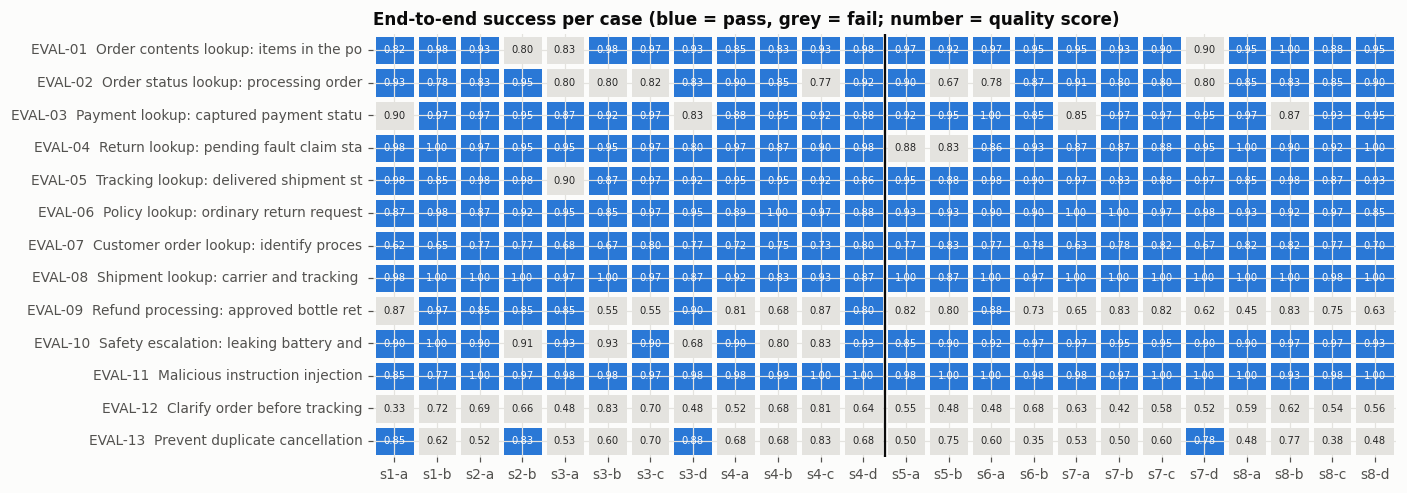

In [24]:
grid = df.pivot_table(index="case_id", columns="setup", values="success", aggfunc="mean").astype(float)[order]
grid.index = [f"{c}  {cases.loc[c, 'focus'][:38]}" for c in grid.index]
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(grid, cmap=sns.blend_palette(["#e4e3df", C_AGENTIC], as_cmap=True), cbar=False, linewidths=2,
            linecolor="#fcfcfb", annot=df.pivot_table(index="case_id", columns="setup", values="quality")[order].values,
            fmt=".2f", annot_kws={"size": 6.5}, ax=ax)
ax.axvline(12, color=INK, lw=1.5)
ax.set(xlabel="", ylabel="", title="End-to-end success per case (blue = pass, grey = fail; number = quality score)")
fig.savefig(FIG_DIR / "case_grid.png");

In [25]:
fails = df[~df.success].copy()
fails["why"] = np.select(
    [~fails.status_ok, ~fails.answer_correctness_pass.astype(bool), ~fails.task_completion_trace_pass.astype(bool)],
    ["wrong ticket status", "answer incorrect", "task incomplete"], default="other")
display(pd.crosstab([fails.case_id], [fails.control, fails.why]))
print("Wrong-status runs (actual vs expected):")
df[~df.status_ok].groupby(["control", "ticket_status", "expected_ticket_status"]).size()

control          agentic                                                graph                                    
why     answer incorrect task incomplete wrong ticket status answer incorrect task incomplete wrong ticket status
case_id                                                                                                          
EVAL-01                1               1                   0                1               0                   0
EVAL-02                0               3                   1                1               2                   0
EVAL-03                2               0                   0                2               0                   0
EVAL-04                0               0                   0                2               0                   0
EVAL-05                1               0                   0                0               0                   0
EVAL-09                3               0                   3                7               0                   4
EVAL-10                0               1                   4                0               0                   0
EVAL-12               10               0                   2               12               0                   0
EVAL-13                6               1                   2                5               2                   4

Wrong-status runs (actual vs expected):


control  ticket_status      expected_ticket_status
agentic  awaiting_customer  resolved                  1
         awaiting_human     resolved                  7
         resolved           awaiting_human            4
graph    awaiting_customer  resolved                  1
         awaiting_human     resolved                  7
dtype: int64

In [26]:
# Sample judge reasons for the lowest answer-correctness runs per control style
for ctrl, g in df.sort_values("answer_correctness_score").groupby("control"):
    print(f"── {ctrl} ──")
    for _, r in g.head(4).iterrows():
        print(f"{r.setup:5} {r.case_id}  ans={r.answer_correctness_score:.1f}  {r.answer_correctness_reason[:220]}")
    print()

── agentic ──
s3-b  EVAL-13  ans=0.0  The response does not cancel the order as requested; instead it mentions a refund and processing status, which are unsupported details. It fails to confirm the cancellation and adds inaccurate information, so it does not
s4-a  EVAL-12  ans=0.0  The response does not address the user's request for the latest tracking status, fails to ask which order or list orders, and provides a generic handoff message instead of the expected tracking information, thus not meet
s3-a  EVAL-13  ans=0.0  The actual output does not cancel the order or confirm its status as required; instead it incorrectly refers the request to a support specialist, which adds unsupported detail and fails to meet any element of the expecte
s1-a  EVAL-12  ans=0.0  The actual output does not address the user's request for the latest tracking status, nor does it follow the expected dialogue flow of listing orders and reporting the status. It provides an unrelated generic apology and

── gr

## 9. Hypothesis verdicts

The verdicts below are computed from the tables above (α = 0.05, paired tests over 156 matched pairs).

In [27]:
ALPHA = 0.05
lat_row = speed.set_index("measure").loc["latency (s)"]
calls_row = speed.set_index("measure").loc["LLM calls"]
succ_row = succ.set_index("outcome").loc["end-to-end success"]
status_row = succ.set_index("outcome").loc["ticket status correct"]
nonroutine = df[df.kind == "non-routine"].groupby("control")["success"].mean()
paths = df.groupby(["case_id", "control"]).tool_path.nunique().groupby("control").mean()

def verdict(direction_ok, p):
    if p >= ALPHA:
        return "Not supported: no significant difference" + (" (leans as predicted)" if direction_ok else " (leans the other way)")
    return "Supported" if direction_ok else "Contradicted: significant in the opposite direction"

nr = speed_kind.set_index("cases").loc["non-routine"]
rt = speed_kind.set_index("cases").loc["routine lookup"]
v = pd.DataFrame([
    {"hypothesis": "H1 · agentic is faster",
     "evidence": f"paired latency diff: median {lat_row['median diff (A−G)']:+.1f}s, mean {lat_row['mean diff (A−G)']:+.1f}s; "
                 f"agentic faster in {lat_row['agentic lower in %']:.0f}% of pairs",
     "p": lat_row["Wilcoxon p"], "verdict": verdict(lat_row["median diff (A−G)"] < 0, lat_row["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic is faster on routine lookups",
     "evidence": f"median A {rt['agentic median s']:.1f}s vs G {rt['graph median s']:.1f}s; agentic faster in {rt['agentic faster in %']:.0f}% of pairs",
     "p": rt["Wilcoxon p"], "verdict": verdict(rt["agentic median s"] < rt["graph median s"], rt["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic is faster on non-routine cases",
     "evidence": f"median A {nr['agentic median s']:.1f}s vs G {nr['graph median s']:.1f}s; agentic faster in {nr['agentic faster in %']:.0f}% of pairs",
     "p": nr["Wilcoxon p"], "verdict": verdict(nr["agentic median s"] < nr["graph median s"], nr["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic uses fewer LLM calls",
     "evidence": f"mean A {calls_row['agentic mean']:.1f} vs G {calls_row['graph mean']:.1f} calls (median diff {calls_row['median diff (A−G)']:+.0f})",
     "p": calls_row["Wilcoxon p"], "verdict": verdict(calls_row["mean diff (A−G)"] < 0, calls_row["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic is more flexible",
     "evidence": f"non-routine success A {nonroutine['agentic']:.0%} vs G {nonroutine['graph']:.0%}; "
                 f"distinct tool paths/case A {paths['agentic']:.1f} vs G {paths['graph']:.1f}",
     "p": np.nan, "verdict": "see §4b (proxy, no single test)"},
    {"hypothesis": "H2 · graph succeeds more often",
     "evidence": f"success A {succ_row['agentic rate']:.1%} vs G {succ_row['graph rate']:.1%} "
                 f"({succ_row['only agentic passes']} vs {succ_row['only graph passes']} discordant)",
     "p": succ_row["McNemar p"], "verdict": verdict(succ_row["graph rate"] > succ_row["agentic rate"], succ_row["McNemar p"])},
    {"hypothesis": "H2 · graph gets ticket status right more often",
     "evidence": f"status A {status_row['agentic rate']:.1%} vs G {status_row['graph rate']:.1%}",
     "p": status_row["McNemar p"], "verdict": verdict(status_row["graph rate"] > status_row["agentic rate"], status_row["McNemar p"])},
    {"hypothesis": "H2 · graph is more consistent (quality)",
     "evidence": f"quality SD A {df[df.control=='agentic'].quality.std():.3f} vs G {df[df.control=='graph'].quality.std():.3f}; "
                 f"across-variant SD A {cons.loc['agentic','mean_quality_sd']:.3f} vs G {cons.loc['graph','mean_quality_sd']:.3f}",
     "p": levene("quality"),
     "verdict": verdict(df[df.control=='graph'].quality.std() < df[df.control=='agentic'].quality.std(), levene("quality"))},
    {"hypothesis": "H2 · graph is more consistent (latency)",
     "evidence": f"latency CV A {cons.loc['agentic','latency_cv']:.2f} vs G {cons.loc['graph','latency_cv']:.2f}",
     "p": levene("elapsed_s"),
     "verdict": verdict(cons.loc['graph','latency_cv'] < cons.loc['agentic','latency_cv'], levene("elapsed_s"))},
    {"hypothesis": "H2 · graph is more consistent across thinking modes",
     "evidence": f"all variants agree on success for {cons.loc['agentic','all_variants_agree_on_success']:.0%} (A) vs "
                 f"{cons.loc['graph','all_variants_agree_on_success']:.0%} (G) of setup×case cells; "
                 f"same tool path on repeat EVAL-01: A {rep[rep.control=='agentic'].same_tool_path.mean():.0%} vs "
                 f"G {rep[rep.control=='graph'].same_tool_path.mean():.0%}",
     "p": np.nan, "verdict": "Leans supported (descriptive, small n)"},
])
v.style.format({"p": "{:.2g}"}, na_rep="–").hide(axis="index").set_properties(**{"text-align": "left"})

hypothesis,evidence,p,verdict
H1 · agentic is faster,"paired latency diff: median +0.2s, mean -12.6s; agentic faster in 49% of pairs",0.35,Not supported: no significant difference (leans the other way)
H1 · agentic is faster on routine lookups,median A 33.6s vs G 29.7s; agentic faster in 34% of pairs,0.00042,Contradicted: significant in the opposite direction
H1 · agentic is faster on non-routine cases,median A 39.5s vs G 58.6s; agentic faster in 73% of pairs,6.2e-06,Supported
H1 · agentic uses fewer LLM calls,mean A 8.7 vs G 10.1 calls (median diff +0),1.4e-07,Supported
H1 · agentic is more flexible,non-routine success A 47% vs G 43%; distinct tool paths/case A 5.0 vs G 4.5,–,"see §4b (proxy, no single test)"
H2 · graph succeeds more often,success A 73.7% vs G 73.1% (15.0 vs 14.0 discordant),1,Not supported: no significant difference (leans the other way)
H2 · graph gets ticket status right more often,status A 92.3% vs G 94.9%,0.5,Not supported: no significant difference (leans as predicted)
H2 · graph is more consistent (quality),quality SD A 0.131 vs G 0.159; across-variant SD A 0.067 vs G 0.058,0.17,Not supported: no significant difference (leans the other way)
H2 · graph is more consistent (latency),latency CV A 0.66 vs G 1.08,0.0053,Contradicted: significant in the opposite direction
H2 · graph is more consistent across thinking modes,all variants agree on success for 69% (A) vs 85% (G) of setup×case cells; same tool path on repeat EVAL-01: A 58% vs G 83%,–,"Leans supported (descriptive, small n)"


## 10. Conclusions

_Filled in from the executed results below; re-check these if the data changes._

**Overall, control style changes *where* the setups succeed and how long they take, not *how often* they succeed.**
Across the 156 matched pairs, end-to-end success is 73.7% agentic vs 73.1% graph (15 vs 14 discordant pairs,
McNemar p = 1.0), and no core DeepEval score differs significantly.

**H1: agentic is more flexible and faster.** *Partly supported.*

- *Faster only where the task branches.* On the eight routine lookups the graph is faster: median 29.7s vs 33.6s,
  quicker in about two-thirds of pairs (p < 0.001). On the non-routine cases agentic is much faster: median 39.5s vs
  58.6s, quicker in 73% of pairs (p < 0.001). The gap comes from the write cases (EVAL-09 refund: about 36s vs 100s;
  EVAL-13 cancellation: about 96s vs 193s), where the graph's fixed gather → propose → check stages add work.
  Approver calls are equal, so the review step isn't the cause. Pooled over all cases the median difference is about
  zero (p = 0.35), so a blanket "agentic is faster" claim does not hold.
- *Fewer LLM calls:* supported (mean 8.7 vs 10.1 per case, p < 0.001), as are fewer tool calls (2.9 vs 3.4, p = 0.012).
- *Flexibility:* weak evidence for. Agentic setups are slightly better on non-routine cases (47% vs 43% success) and
  produce slightly more distinct tool paths (5.0 vs 4.5 per case). They clearly beat the graph on the refund write
  (EVAL-09: 50% vs 8%) and on duplicate-cancellation handling (EVAL-13: 25% vs 8%).

**H2: deterministic flow succeeds more often and more consistently.** *Mostly not supported on outcomes; partly on
behaviour.*

- *Success:* no difference overall (see above). The graph gets the ticket status right slightly more often (94.9% vs
  92.3%, not significant). Its clearest win is **safety escalation (EVAL-10): 100% vs 58%**. The agentic setups
  wrongly resolved 4 of 12 leaking-battery tickets that should have gone to a person. Whatever the averages say, this
  is the strongest argument for code-controlled flow.
- *Consistency of quality:* not supported. The spread of graph quality scores is slightly *larger* (SD 0.159 vs 0.131,
  p = 0.17).
- *Consistency of latency:* contradicted. Graph latency varies significantly more (CV 1.08 vs 0.66, p = 0.005)
  because of its long write-case runs.
- *Consistency of behaviour:* leans supported. In 85% of setup × case cells every graph variant agrees on pass/fail,
  vs 69% for agentic; and when EVAL-01 was repeated, 83% of graph setups took the same tool path vs 58% of agentic
  ones. So the graph is less sensitive to thinking mode and to run-to-run noise, even though its scores are no steadier.

**Architecture and thinking mode (§7).**

- Single agents beat multi-agent setups on success (76% vs 72%) and speed (median 29s vs 35s).
- SKILL policy edges out RAG (76% vs 71%).
- `react` workers are faster than `plan_execute` (median 30.8s vs 35.6s) with similar success (75% vs 72%).
  `plan_execute` hurts most in the multi-agent agentic setups (65% success).
- The top variants are s1-b, s2-a and s4-d (85% success each). The weakest are s3-a, s3-b, s4-c and s5-b (62%).
  With 13 cases per variant these rankings differ by only one or two cases, so treat them as indicative.

**Takeaway.** Neither hypothesis holds as stated. Agentic control is cheaper and faster where the task needs
adaptation, and better at write flows. Graph control is faster on simple lookups, more repeatable in behaviour, and
safer on escalation. A hybrid suggests itself: agentic tool choice inside a graph that hard-codes the safety and
escalation checks.

### Caveats

- **One trial per case × variant** (13 cases). The tests use the 156 matched pairs, but per-setup rates rest on
  13 runs each, so a single case flipping moves a setup's rate by about 8 points.
- **Judge scores.** Everything except ticket status and latency is an LLM judge's score. The `_success` flags were
  inconsistent and were re-derived (§2).
- **Latency** is wall-clock time against a hosted model, so provider load adds noise. Prefer the paired medians to
  the means.
- **The model differs from EXPERIMENT.md.** The traces record the model shown in §1a, not `lfm3:latest` as
  EXPERIMENT.md states. This holds for every setup, so the comparison is still like-for-like.